In [9]:
from pathlib import Path
import sys
import joblib

PROJECT_ROOT = Path(
    "/Users/hongmo/Desktop/Gradient Boosting"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_and_split_data

# Load saved pipeline
model_path = PROJECT_ROOT / "outputs" / "xgboost_refitted.joblib"
final_pipeline = joblib.load(model_path)

# Reproduce the same data split
data_path = PROJECT_ROOT / "data" / "application_train.csv"

X_train, X_val, X_test, y_train, y_val, y_test = (
    load_and_split_data(data_path)
)

# Predict validation probabilities
y_val_prob = final_pipeline.predict_proba(X_val)[:, 1]

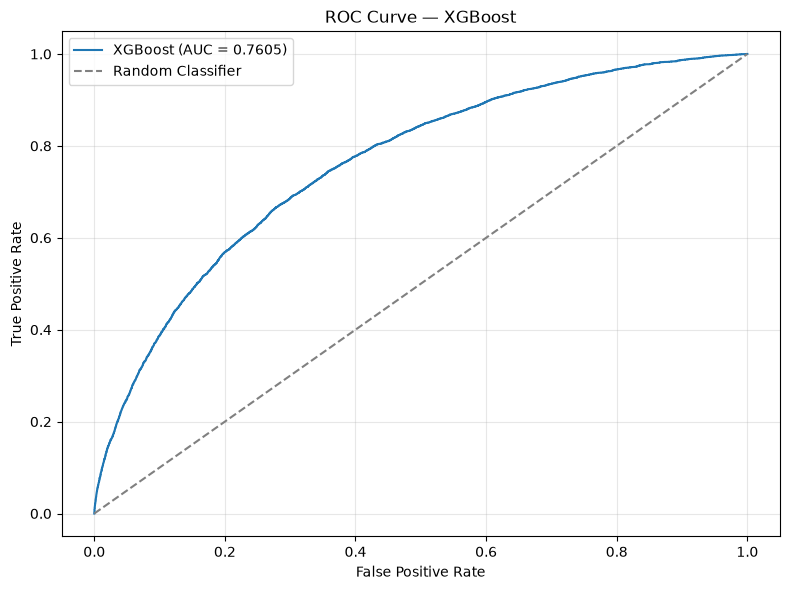

In [10]:
from src.evaluation import plot_roc_curve

plot_roc_curve(y_val, y_val_prob)

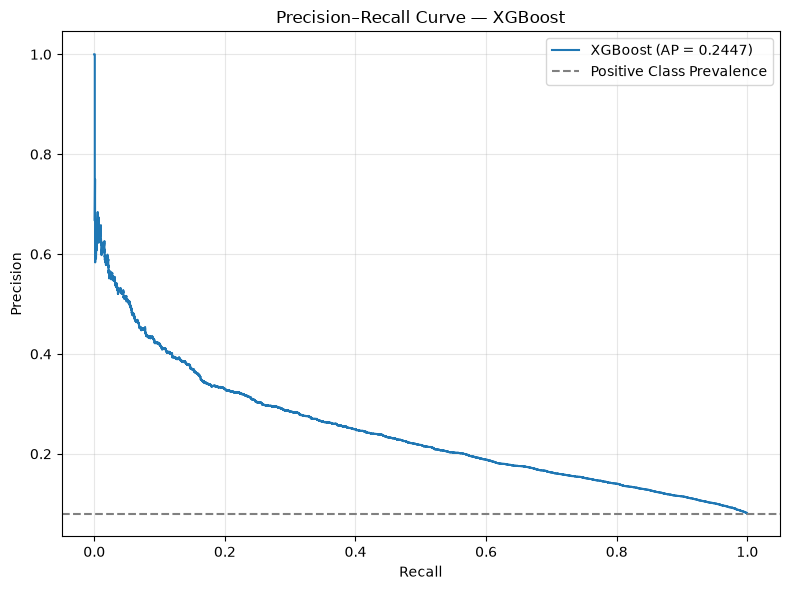

In [11]:
import importlib
import src.evaluation as evaluation

importlib.reload(evaluation)

evaluation.plot_precision_recall_curve(
    y_val,
    y_val_prob
)

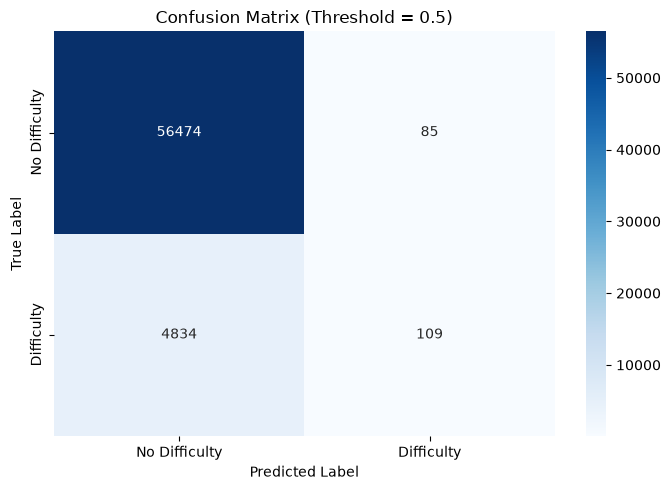

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56559
           1       0.56      0.02      0.04      4943

    accuracy                           0.92     61502
   macro avg       0.74      0.51      0.50     61502
weighted avg       0.89      0.92      0.88     61502



In [12]:
from src.evaluation import plot_confusion_matrix

plot_confusion_matrix(
    y_val,
    y_val_prob,
    threshold=0.5
)

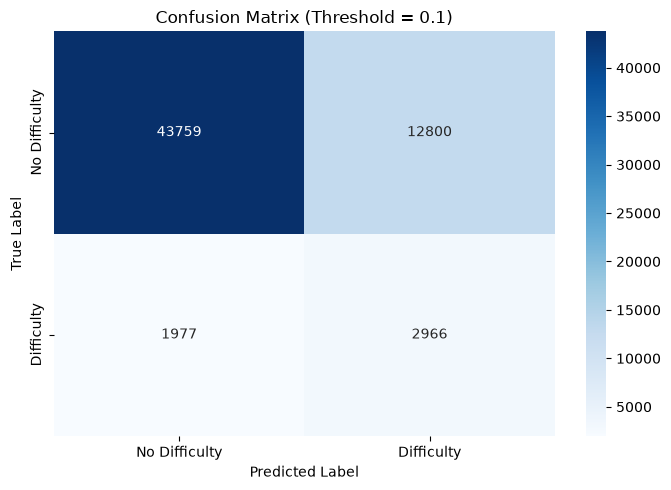

              precision    recall  f1-score   support

           0       0.96      0.77      0.86     56559
           1       0.19      0.60      0.29      4943

    accuracy                           0.76     61502
   macro avg       0.57      0.69      0.57     61502
weighted avg       0.89      0.76      0.81     61502



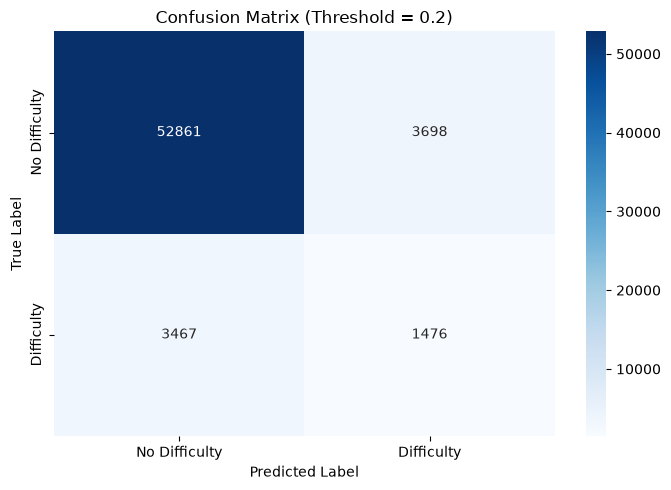

              precision    recall  f1-score   support

           0       0.94      0.93      0.94     56559
           1       0.29      0.30      0.29      4943

    accuracy                           0.88     61502
   macro avg       0.61      0.62      0.61     61502
weighted avg       0.89      0.88      0.88     61502



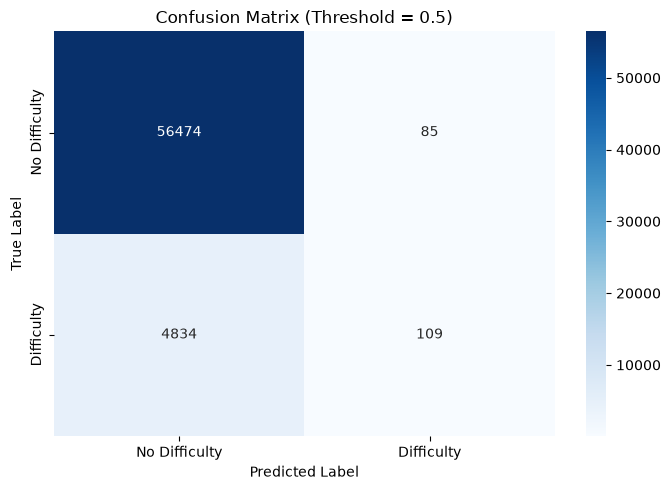

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56559
           1       0.56      0.02      0.04      4943

    accuracy                           0.92     61502
   macro avg       0.74      0.51      0.50     61502
weighted avg       0.89      0.92      0.88     61502



In [13]:
for threshold in [0.1, 0.2, 0.5]:
    plot_confusion_matrix(
        y_val,
        y_val_prob,
        threshold=threshold
    )

In [15]:
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

results = []

for threshold in [0.1, 0.2, 0.5]:

    y_pred = (y_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1": f1_score(y_val, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_val, y_pred),
        "False Positives": fp,
        "False Negatives": fn
    })

threshold_comparison = pd.DataFrame(results)

display(threshold_comparison.round(4))

,Threshold,Precision,Recall,F1,Accuracy,False Positives,False Negatives
0,0.1,0.1881,0.6000,0.2864,0.7597,12800,1977
1,0.2,0.2853,0.2986,0.2918,0.8835,3698,3467
2,0.5,0.5619,0.0221,0.0424,0.9200,85,4834


In [ ]:
import importlib
import src.evaluation as evaluation

# Reload updated evaluation module
importlib.reload(evaluation)

# Plot feature importance
importance_df = evaluation.plot_feature_importance(
    final_pipeline,
    top_n=20
)

display(importance_df.head(20))

In [18]:
from pathlib import Path

PROJECT_ROOT = Path("/Users/hongmo/Desktop/Gradient Boosting")

figure_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "xgboost_feature_importance.png"
)

figure_path.parent.mkdir(parents=True, exist_ok=True)

FileNotFoundError: [Errno 2] No such file or directory: 'outputs/figures/xgboost_feature_importance.png'

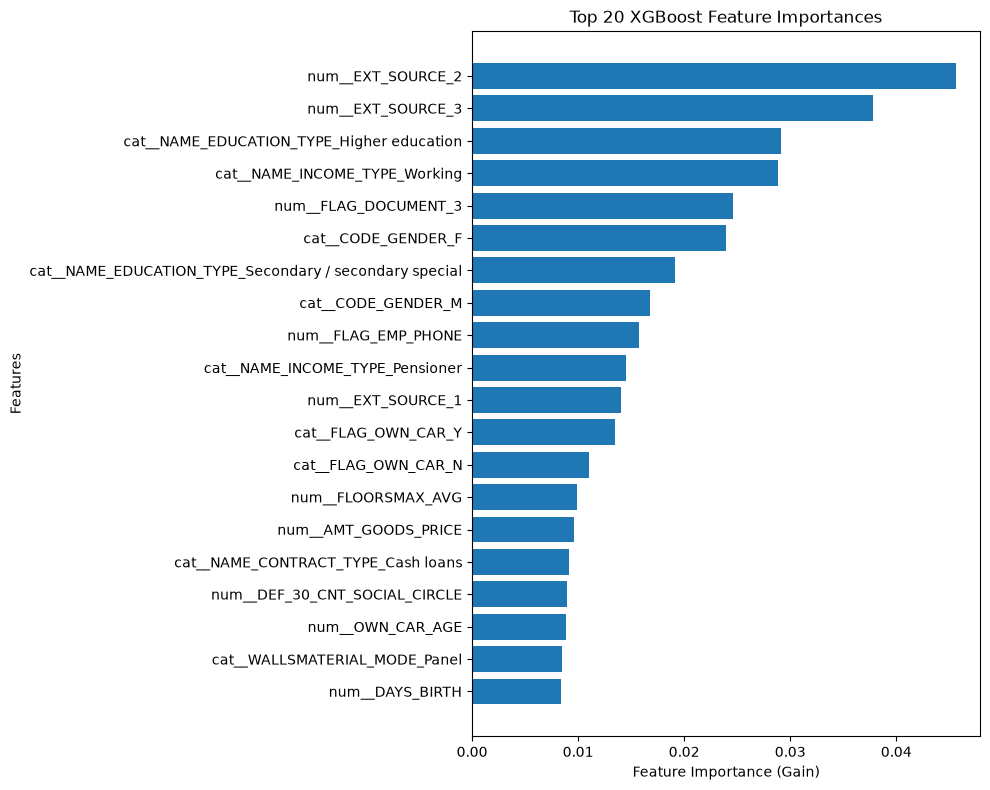

In [20]:
import importlib
import src.evaluation as evaluation

importlib.reload(evaluation)

importance_df = evaluation.plot_feature_importance(
    final_pipeline,
    top_n=20,
    save_path=figure_path
)

/Users/hongmo/Desktop/Gradient Boosting/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


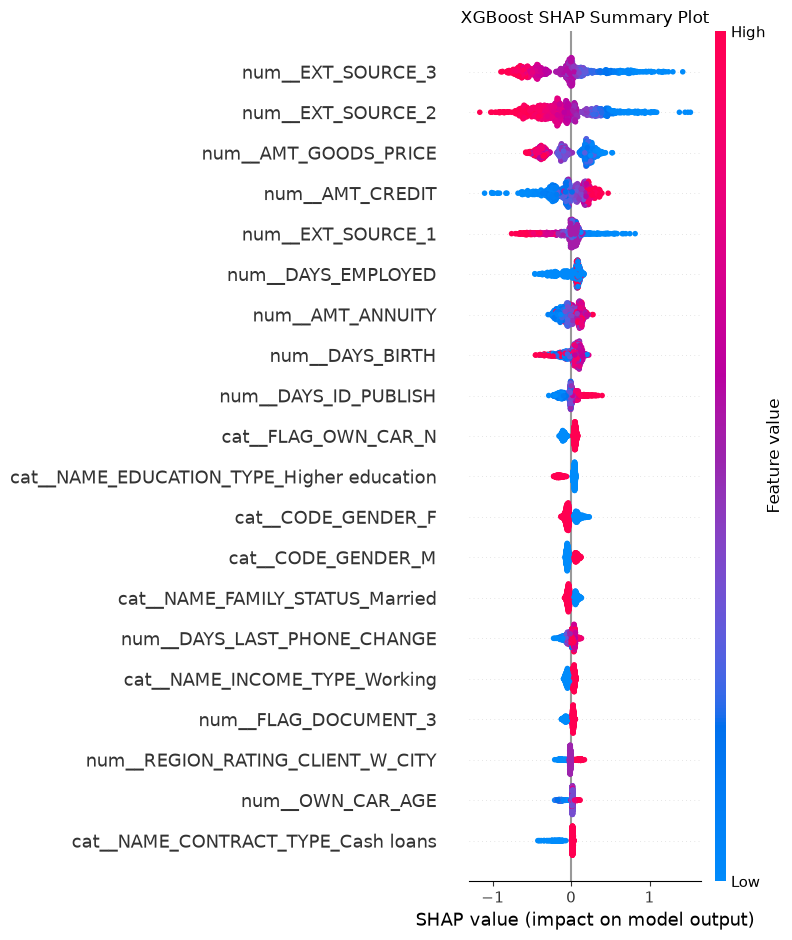

In [21]:
import importlib
import src.interpretation as interpretation

importlib.reload(interpretation)

shap_values = interpretation.plot_shap_summary(
    final_pipeline,
    X_val,
    sample_size=1000
)